# Regresja i SVM — notebook z wykładu

Jeden plik, trzy części w kolejności z wykładu:

1. **Regresja liniowa (MNK)** — przewidujemy cenę mieszkania na podstawie powierzchni,
2. **Regresja wielomianowa** — lot piłki, sztuczka z cechą x², przeuczenie i wybór stopnia,
3. **SVM** — margines, wektory podpierające, kernel trick.

Komórki wykonuj po kolei, od góry do dołu. Każda część jest samodzielna:
sama tworzy swoje dane i sama importuje to, czego potrzebuje.

---

# Część 1 — Regresja liniowa (MNK)

W tej części przeprowadzimy **algorytm MNK krok po kroku** na prostym przykładzie:
przewidujemy **cenę mieszkania** na podstawie jego **powierzchni**.

Plan:
1. generujemy dane,
2. dopasowujemy prostą metodą najmniejszych kwadratów,
3. rysujemy prostą i reszty (błędy),
4. oceniamy dopasowanie współczynnikiem R²,
5. przewidujemy cenę konkretnego mieszkania,
6. bonus: sprawdzamy, że wzory z wykładu dają dokładnie ten sam wynik.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

## Krok 1 — dane

Mamy 30 mieszkań. Cena zależy głównie od powierzchni, ale rynek bywa nieprzewidywalny:
stan mieszkania, piętro, dzielnica, targowanie się... Dlatego punkty są mocno **rozbite** —
na pierwszy rzut oka trudno powiedzieć, gdzie powinna przebiegać prosta.

In [2]:
# ziarno losowości — dzięki niemu za każdym razem dostaniemy te same dane
rng = np.random.default_rng(seed=42)

# powierzchnie mieszkań: 30 mieszkań, od 20 do 80 m^2
powierzchnia = rng.uniform(20, 80, size=30)

# cena w tys. zł: 9 tys. za każdy m^2 + 60 tys. "za samo mieszkanie" + duży szum
szum = rng.normal(0, 90, size=30)
cena = 9 * powierzchnia + 60 + szum

# scikit-learn oczekuje cech w formie "kolumny" (macierz 2D)
X = powierzchnia.reshape(-1, 1)
y = cena

print(f"Liczba mieszkań: {len(powierzchnia)}")

Liczba mieszkań: 30


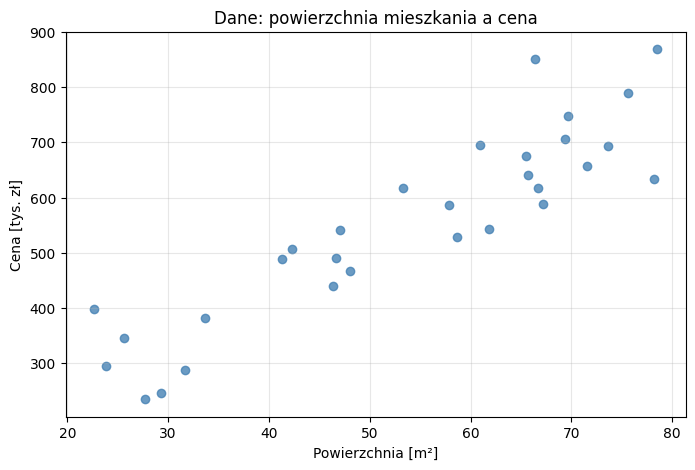

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(powierzchnia, cena, color="steelblue", alpha=0.8)
plt.xlabel("Powierzchnia [m²]")
plt.ylabel("Cena [tys. zł]")
plt.title("Dane: powierzchnia mieszkania a cena")
plt.grid(alpha=0.3)
plt.show()

## Krok 2 — dopasowujemy prostą (MNK)

**Zanim uruchomisz komórkę: spróbuj zgadnąć, gdzie powinna przebiegać prosta.**

`LinearRegression` z scikit-learn implementuje metodę najmniejszych kwadratów:
szuka takiej prostej, dla której **suma kwadratów reszt jest najmniejsza**.

In [4]:
model = LinearRegression()
model.fit(X, y)

a = model.coef_[0]      # nachylenie: o ile droższe mieszkanie za każdy dodatkowy m^2
b = model.intercept_    # wyraz wolny: "cena startowa" przy zerowej powierzchni

print(f"Dopasowana prosta:  cena = {a:.2f} * powierzchnia + {b:.2f}  [tys. zł]")

Dopasowana prosta:  cena = 8.78 * powierzchnia + 82.07  [tys. zł]


## Krok 3 — prosta na wykresie

Porównaj z Twoim zgadywaniem z Kroku 2 — blisko?

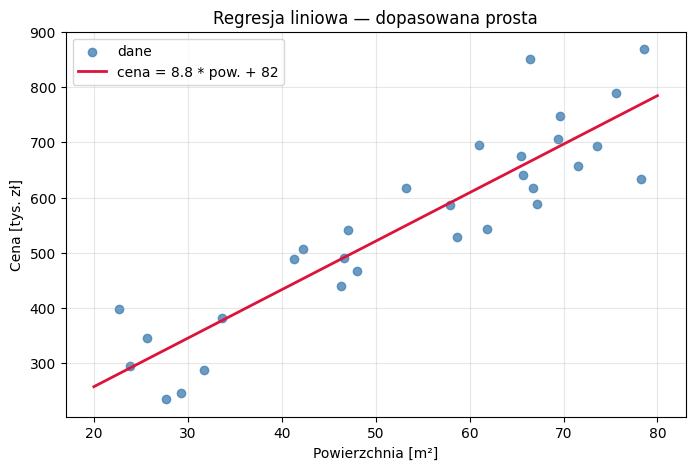

In [5]:
# prosta rysowana od najmniejszej do największej powierzchni
x_linia = np.linspace(20, 80, 100)
y_linia = a * x_linia + b

plt.figure(figsize=(8, 5))
plt.scatter(powierzchnia, cena, color="steelblue", alpha=0.8, label="dane")
plt.plot(x_linia, y_linia, color="crimson", linewidth=2, label=f"cena = {a:.1f} * pow. + {b:.0f}")
plt.xlabel("Powierzchnia [m²]")
plt.ylabel("Cena [tys. zł]")
plt.title("Regresja liniowa — dopasowana prosta")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Krok 4 — reszty: o ile model się myli

**Reszta = wartość rzeczywista − wartość przewidziana.**
To pionowa odległość punktu od prostej. MNK minimalizuje sumę ich kwadratów.

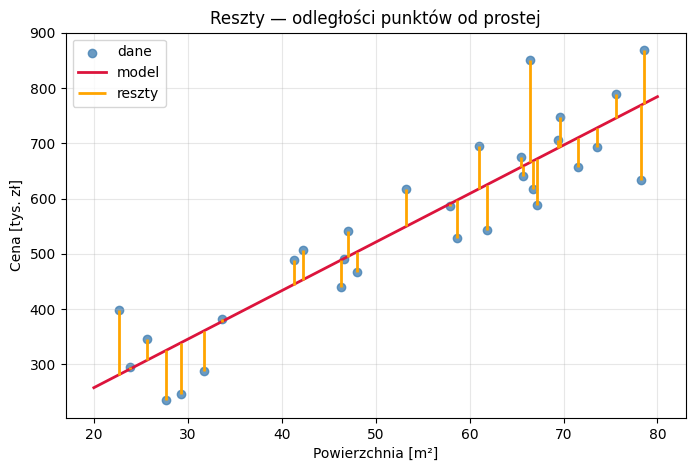

Suma kwadratów reszt: 151667 (tys. zł)^2


In [6]:
y_przewidziane = model.predict(X)
reszty = y - y_przewidziane

plt.figure(figsize=(8, 5))
plt.scatter(powierzchnia, cena, color="steelblue", alpha=0.8, label="dane")
plt.plot(x_linia, y_linia, color="crimson", linewidth=2, label="model")

# pomarańczowe kreski pokazują reszty
plt.vlines(powierzchnia, y, y_przewidziane, color="orange", linewidth=2, label="reszty")

plt.xlabel("Powierzchnia [m²]")
plt.ylabel("Cena [tys. zł]")
plt.title("Reszty — odległości punktów od prostej")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Suma kwadratów reszt: {np.sum(reszty ** 2):.0f} (tys. zł)^2")

## Krok 5 — ocena dopasowania: R²

R² porównuje błąd naszej prostej z błędem "głupiego" modelu, który zawsze zgaduje średnią:
**R² = 1 − (błąd prostej / błąd średniej)**.
R² = 1 → idealnie, R² = 0 → prosta nic nie wnosi.

In [7]:
r2 = r2_score(y, y_przewidziane)

print(f"R² = {r2:.3f}")
print("Im bliżej 1, tym lepiej prosta opisuje dane.")

R² = 0.823
Im bliżej 1, tym lepiej prosta opisuje dane.


## Krok 6 — przewidywanie ceny konkretnego mieszkania

In [8]:
nowe_mieszkanie = np.array([[55]])   # mieszkanie o powierzchni 55 m^2
przewidywana_cena = model.predict(nowe_mieszkanie)[0]

print(f"Mieszkanie 55 m^2 -> przewidywana cena: {przewidywana_cena:.0f} tys. zł")

Mieszkanie 55 m^2 -> przewidywana cena: 565 tys. zł


## Bonus — wzory z wykładu dają ten sam wynik

Przepis z wykładu (bez dowodu):
- a = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)²
- b = ȳ − a·x̄

In [9]:
x_srednia = powierzchnia.mean()
y_srednia = cena.mean()

a_recznie = np.sum((powierzchnia - x_srednia) * (cena - y_srednia)) / np.sum((powierzchnia - x_srednia) ** 2)
b_recznie = y_srednia - a_recznie * x_srednia

print(f"scikit-learn:    a = {a:.4f}, b = {b:.4f}")
print(f"wzory z wykładu: a = {a_recznie:.4f}, b = {b_recznie:.4f}")

scikit-learn:    a = 8.7790, b = 82.0737
wzory z wykładu: a = 8.7790, b = 82.0737


## Wnioski

- prosta **cena = a·powierzchnia + b** to nasz model: `a` — o ile droższe mieszkanie za każdy m², `b` — "cena startowa",
- MNK wybiera prostą z **najmniejszą sumą kwadratów reszt**,
- nawet przy mocno rozbitych danych MNK znajduje ukryty trend,
- **R²** bliskie 1 = dobre dopasowanie (ale R² = 1 bywa podejrzane — dane prawdziwe zawsze mają szum),
- model przewiduje **liczby** — to regresja.

---

# Część 2 — Regresja wielomianowa

Czasem dane układają się w krzywą, a nie w prostą — np. **wysokość piłki w czasie lotu**
(rzut pionowy: piłka wznosi się i opada).

Plan:
1. generujemy dane w kształcie paraboli,
2. próbujemy dopasować prostą (za mało elastyczną),
3. używamy sztuczki z nową cechą x²,
4. sprawdzamy, co się dzieje przy większych stopniach (przeuczenie),
5. wybieramy stopień na danych testowych.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

## Krok 1 — dane: lot piłki

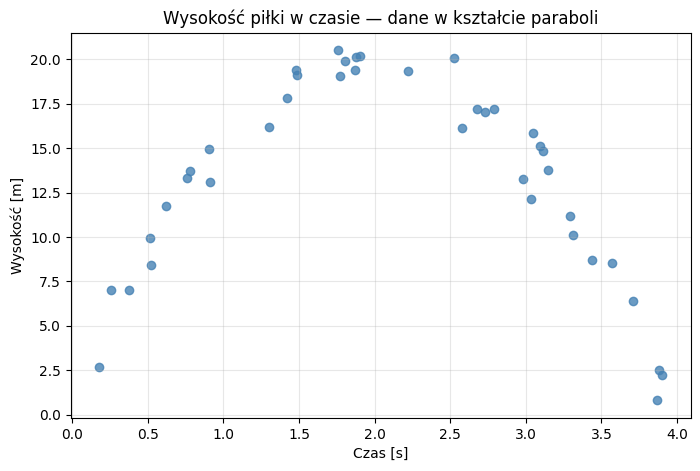

In [11]:
rng = np.random.default_rng(seed=42)

# czas lotu piłki: 40 pomiarów od 0 do 4 sekund
czas = rng.uniform(0, 4, size=40)

# wysokość = parabola + szum (rzut pionowy w polu grawitacyjnym)
wysokosc = 20 * czas - 5 * czas**2 + rng.normal(0, 1.5, size=40)

X = czas.reshape(-1, 1)
y = wysokosc

plt.figure(figsize=(8, 5))
plt.scatter(czas, wysokosc, color="steelblue", alpha=0.8)
plt.xlabel("Czas [s]")
plt.ylabel("Wysokość [m]")
plt.title("Wysokość piłki w czasie — dane w kształcie paraboli")
plt.grid(alpha=0.3)
plt.show()

## Krok 2 — prosta nie wystarcza

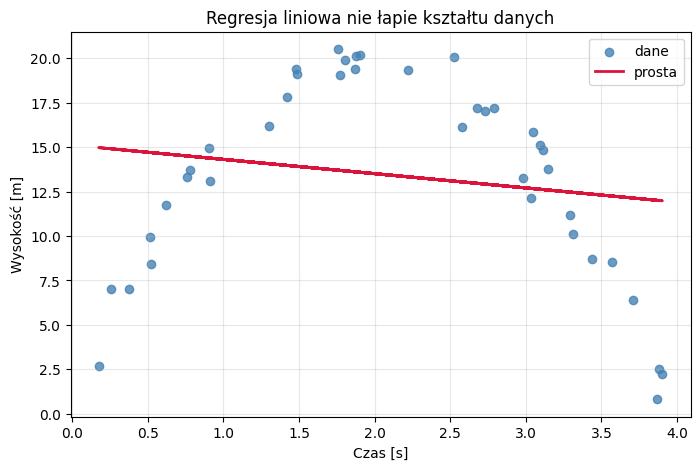

In [12]:
model_prosta = LinearRegression()
model_prosta.fit(X, y)

plt.figure(figsize=(8, 5))
plt.scatter(czas, wysokosc, color="steelblue", alpha=0.8, label="dane")
plt.plot(czas, model_prosta.predict(X), color="crimson", linewidth=2, label="prosta")
plt.xlabel("Czas [s]")
plt.ylabel("Wysokość [m]")
plt.title("Regresja liniowa nie łapie kształtu danych")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Krok 3 — sztuczka: nowa cecha x²

Tworzymy **drugą kolumnę** zawierającą x². Potem robimy **zwykłą regresję liniową
na dwóch kolumnach** — dokładnie ta sama idea co na wykładzie ("wielomian to
przebrana regresja liniowa").

In [13]:
# PolynomialFeatures tworzy nowe kolumny: [x, x^2]
poly = PolynomialFeatures(degree=2, include_bias=False)
X_wielomian = poly.fit_transform(X)

print("Pierwsze 3 wiersze — kolumny [x, x^2]:")
print(X_wielomian[:3])

Pierwsze 3 wiersze — kolumny [x, x^2]:
[[ 3.09582419  9.58412744]
 [ 1.75551376  3.08182856]
 [ 3.43439168 11.79504621]]


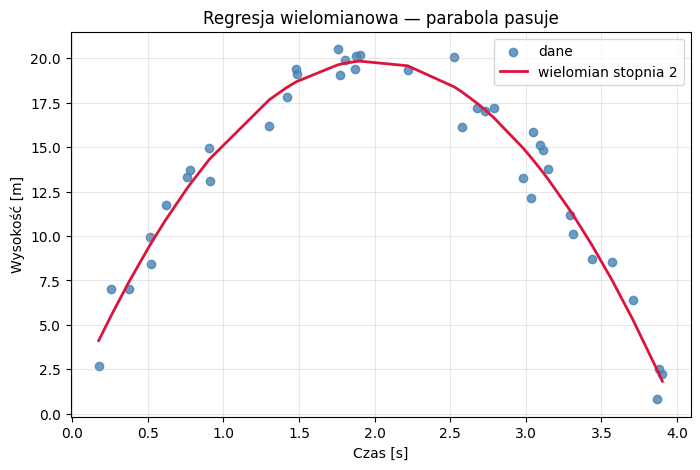

In [14]:
model_wielomian = LinearRegression()
model_wielomian.fit(X_wielomian, y)

# do rysowania krzywej sortujemy punkty po czasie
kolejnosc = np.argsort(czas)

plt.figure(figsize=(8, 5))
plt.scatter(czas, wysokosc, color="steelblue", alpha=0.8, label="dane")
plt.plot(czas[kolejnosc], model_wielomian.predict(X_wielomian[kolejnosc]),
         color="crimson", linewidth=2, label="wielomian stopnia 2")
plt.xlabel("Czas [s]")
plt.ylabel("Wysokość [m]")
plt.title("Regresja wielomianowa — parabola pasuje")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Krok 4 — większy stopień = ryzyko przeuczenia

Stopień 9 "prześlizguje się" przez punkty — zamiast trendu łapie **szum**.

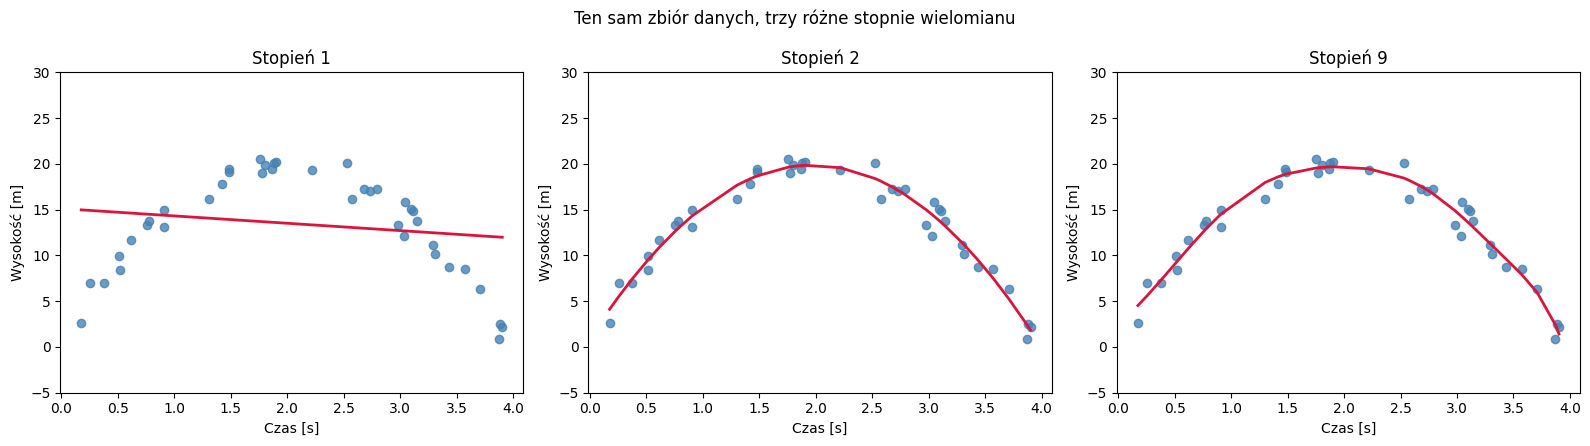

In [15]:
stopnie = [1, 2, 9]

fig, osie = plt.subplots(1, 3, figsize=(16, 4.5))

for os, stopien in zip(osie, stopnie):
    # nowe cechy: x, x^2, ..., x^stopien
    poly = PolynomialFeatures(degree=stopien, include_bias=False)
    X_p = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_p, y)

    os.scatter(czas, wysokosc, color="steelblue", alpha=0.8)
    os.plot(czas[kolejnosc], model.predict(X_p[kolejnosc]), color="crimson", linewidth=2)
    os.set_title(f"Stopień {stopien}")
    os.set_xlabel("Czas [s]")
    os.set_ylabel("Wysokość [m]")
    os.set_ylim(-5, 30)

plt.suptitle("Ten sam zbiór danych, trzy różne stopnie wielomianu")
plt.tight_layout()
plt.show()

## Krok 5 — jak wybrać stopień? Dane treningowe vs testowe

1. dzielimy dane na **treningowe** (do nauki modelu) i **testowe** (odłożone "pod szkło"),
2. uczymy model **tylko** na danych treningowych,
3. mierzymy błąd osobno na obu zbiorach,
4. wybieramy stopień na dnie "doliny" błędu testowego.

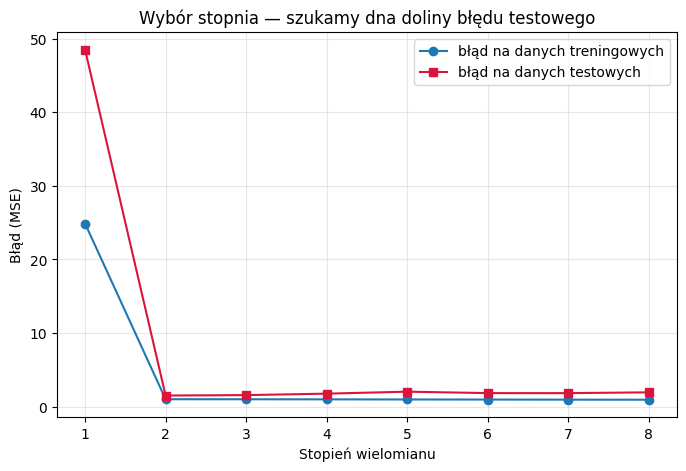

Najlepszy stopień według danych testowych: 2


In [16]:
# 70% danych do nauki, 30% do sprawdzenia
X_tren, X_test, y_tren, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

stopnie = range(1, 9)
blad_trening = []
blad_test = []

for stopien in stopnie:
    # nowe cechy: x, x^2, ..., x^stopien
    poly = PolynomialFeatures(degree=stopien, include_bias=False)
    X_tren_p = poly.fit_transform(X_tren)
    X_test_p = poly.transform(X_test)

    # model uczymy TYLKO na danych treningowych
    model = LinearRegression()
    model.fit(X_tren_p, y_tren)

    # błąd mierzymy osobno na obu zbiorach
    blad_trening.append(mean_squared_error(y_tren, model.predict(X_tren_p)))
    blad_test.append(mean_squared_error(y_test, model.predict(X_test_p)))

plt.figure(figsize=(8, 5))
plt.plot(stopnie, blad_trening, "o-", label="błąd na danych treningowych")
plt.plot(stopnie, blad_test, "s-", color="crimson", label="błąd na danych testowych")
plt.xlabel("Stopień wielomianu")
plt.ylabel("Błąd (MSE)")
plt.title("Wybór stopnia — szukamy dna doliny błędu testowego")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

najlepszy_stopien = list(stopnie)[int(np.argmin(blad_test))]
print(f"Najlepszy stopień według danych testowych: {najlepszy_stopien}")

## Wnioski

- regresja wielomianowa = regresja liniowa na "przebranych" cechach (x, x², x³, ...),
- za niski stopień → **niedouczenie**, za wysoki → **przeuczenie**,
- o stopniu decydujemy na danych **testowych**, których model nie widział,
- współczynniki znajduje komputer — my wybieramy tylko stopień.

---

# Część 3 — SVM (maszyna wektorów nośnych)

SVM to algorytm **klasyfikacji**: przydziela punkty do grup.
Idea: granica między klasami powinna przebiegać **środkiem najszerszej możliwej
"ulicy"** (marginesu).

Plan:
1. generujemy dwie grupy punktów,
2. uczymy SVM liniowy i rysujemy margines z wektorami podpierającymi,
3. klasyfikujemy nowy punkt,
4. pokazujemy dane, których prosta nie rozdzieli,
5. ratujemy się kernelem RBF (sztuczka kernelowa),
6. porównujemy trzy kernele.

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_circles
from sklearn.svm import SVC

## Krok 1 — dwie grupy punktów

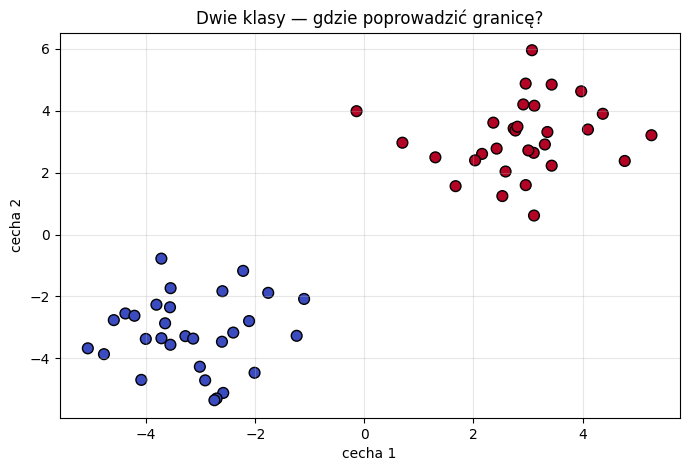

In [18]:
# dwie chmury punktów: klasa 0 (lewy dolny róg) i klasa 1 (prawy górny)
X, y = make_blobs(n_samples=60, centers=[(-3, -3), (3, 3)], cluster_std=1.2, random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=60, edgecolors="k")
plt.xlabel("cecha 1")
plt.ylabel("cecha 2")
plt.title("Dwie klasy — gdzie poprowadzić granicę?")
plt.grid(alpha=0.3)
plt.show()

## Krok 2 — uczymy SVM

- `kernel="linear"` → granicą jest prosta (jak na wykładzie),
- duże `C` → "twardy" margines: model prawie nie pozwala sobie na wyjątki.

In [19]:
svm = SVC(kernel="linear", C=1000)
svm.fit(X, y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


## Krok 3 — granica, margines i wektory podpierające

Na wykresie:
- **linia ciągła** = granica decyzji (środek ulicy),
- **linie przerywane** = krawędzie ulicy (marginesu),
- **obwódki wokół punktów** = wektory podpierające — tylko one decydują o granicy.

In [20]:
def narysuj_svm(model, X, os):
    # siatka punktów pokrywająca cały wykres
    x_zakres = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300)
    y_zakres = np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300)
    siatka_x, siatka_y = np.meshgrid(x_zakres, y_zakres)
    punkty = np.c_[siatka_x.ravel(), siatka_y.ravel()]

    # decision_function: odległość punktu od granicy (ze znakiem)
    decyzje = model.decision_function(punkty).reshape(siatka_x.shape)

    # kolorowe tło = obszary dwóch klas
    os.contourf(siatka_x, siatka_y, decyzje > 0, cmap="coolwarm", alpha=0.15)

    # poziomy -1 i 1 to krawędzie "ulicy", poziom 0 to granica decyzji
    os.contour(siatka_x, siatka_y, decyzje, levels=[-1, 0, 1],
               linestyles=["--", "-", "--"], colors="k", linewidths=[1, 2, 1])

    # wektory podpierające = punkty leżące na krawędziach ulicy
    os.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
               s=160, facecolors="none", edgecolors="k", linewidths=2)

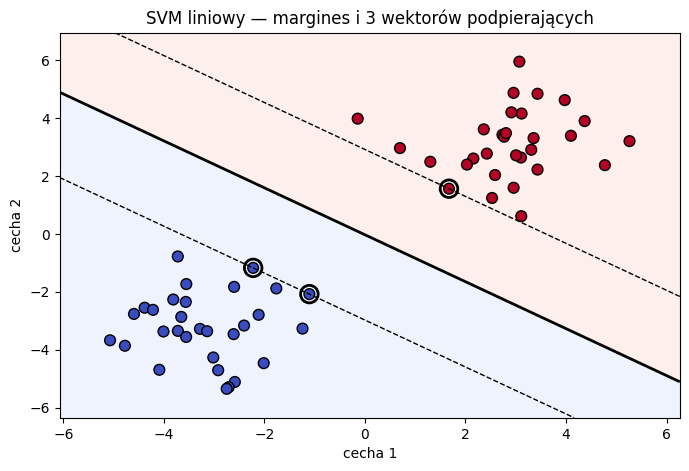

In [21]:
fig, os = plt.subplots(figsize=(8, 5))
narysuj_svm(svm, X, os)
os.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=60, edgecolors="k")
os.set_xlabel("cecha 1")
os.set_ylabel("cecha 2")
os.set_title(f"SVM liniowy — margines i {len(svm.support_vectors_)} wektorów podpierających")
plt.show()

## Krok 4 — klasyfikacja nowego punktu

Nowy punkt trafia po jednej stronie granicy → dostaje klasę.
Odległość od granicy to "pewność" decyzji: im dalej, tym pewniej.

In [22]:
nowy_punkt = np.array([[2, 2]])   # współrzędne: (cecha 1, cecha 2)

klasa = svm.predict(nowy_punkt)[0]
odleglosc = svm.decision_function(nowy_punkt)[0]

print(f"Nowy punkt (2, 2) -> klasa {klasa}")
print(f"Odległość od granicy: {odleglosc:.2f} (im większa, tym pewniejsza decyzja)")

Nowy punkt (2, 2) -> klasa 1
Odległość od granicy: 1.24 (im większa, tym pewniejsza decyzja)


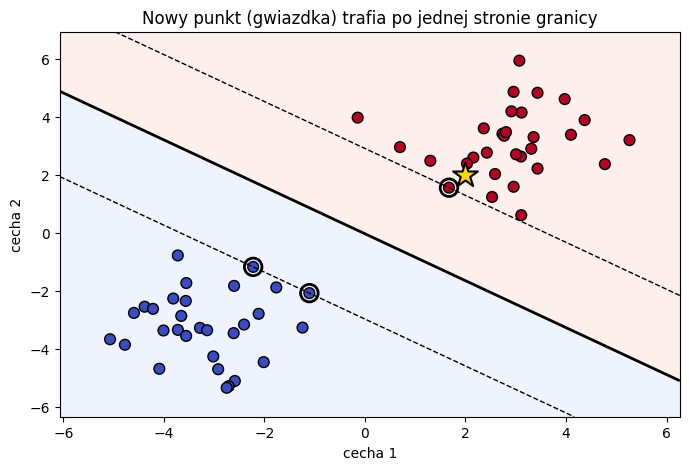

In [23]:
fig, os = plt.subplots(figsize=(8, 5))
narysuj_svm(svm, X, os)
os.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=60, edgecolors="k")
os.scatter(2, 2, marker="*", s=350, color="gold", edgecolors="k", linewidths=1.5)
os.set_xlabel("cecha 1")
os.set_ylabel("cecha 2")
os.set_title("Nowy punkt (gwiazdka) trafia po jednej stronie granicy")
plt.show()

## Krok 5 — dane, których nie rozdzieli żadna prosta

Jedna klasa w kółku, druga wokół — to klasyczny przykład danych nieliniowych.

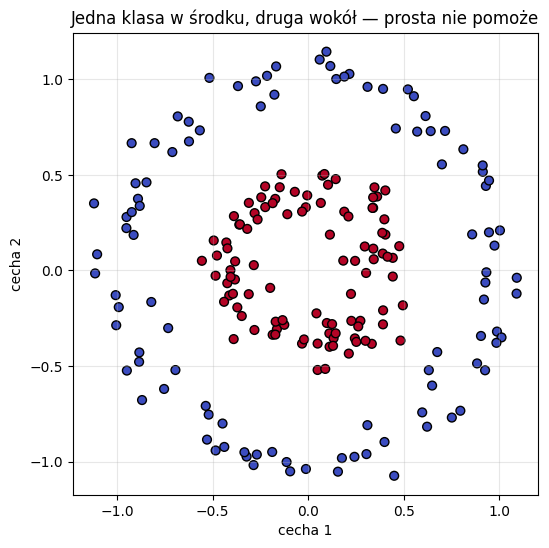

In [24]:
X_kolo, y_kolo = make_circles(n_samples=200, factor=0.4, noise=0.08, random_state=42)

plt.figure(figsize=(6, 6))
plt.scatter(X_kolo[:, 0], X_kolo[:, 1], c=y_kolo, cmap="coolwarm", s=40, edgecolors="k")
plt.xlabel("cecha 1")
plt.ylabel("cecha 2")
plt.title("Jedna klasa w środku, druga wokół — prosta nie pomoże")
plt.axis("equal")
plt.grid(alpha=0.3)
plt.show()

## Krok 6 — kernel liniowy zawodzi

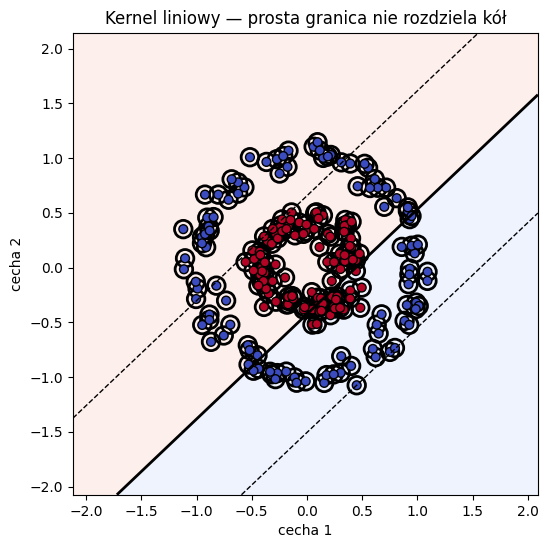

In [25]:
svm_liniowy = SVC(kernel="linear", C=1000)
svm_liniowy.fit(X_kolo, y_kolo)

fig, os = plt.subplots(figsize=(6, 6))
narysuj_svm(svm_liniowy, X_kolo, os)
os.scatter(X_kolo[:, 0], X_kolo[:, 1], c=y_kolo, cmap="coolwarm", s=40, edgecolors="k")
os.set_xlabel("cecha 1")
os.set_ylabel("cecha 2")
os.set_title("Kernel liniowy — prosta granica nie rozdziela kół")
plt.show()

## Krok 7 — kernel RBF: sztuczka kernelowa w akcji

Kernel RBF liczy **podobieństwo** par punktów (1 = praktycznie identyczne,
0 = bardzo odległe). SVM działa na tych podobieństwach — tak, jakby dane
zostały "rozplecione" w wyższym wymiarze, choć nigdy tam nie liczymy współrzędnych.
Efekt: z zewnątrz granica może wyglądać jak okrąg.

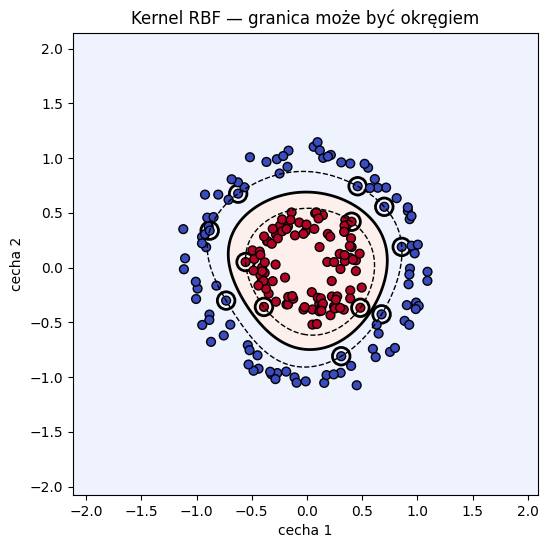

Liczba wektorów podpierających: 12


In [26]:
svm_rbf = SVC(kernel="rbf", C=1000)
svm_rbf.fit(X_kolo, y_kolo)

fig, os = plt.subplots(figsize=(6, 6))
narysuj_svm(svm_rbf, X_kolo, os)
os.scatter(X_kolo[:, 0], X_kolo[:, 1], c=y_kolo, cmap="coolwarm", s=40, edgecolors="k")
os.set_xlabel("cecha 1")
os.set_ylabel("cecha 2")
os.set_title("Kernel RBF — granica może być okręgiem")
plt.show()

print(f"Liczba wektorów podpierających: {len(svm_rbf.support_vectors_)}")

## Krok 8 — porównanie kerneli

Ten sam SVM, trzy kernele: liniowy, wielomianowy i RBF (gaussowski).

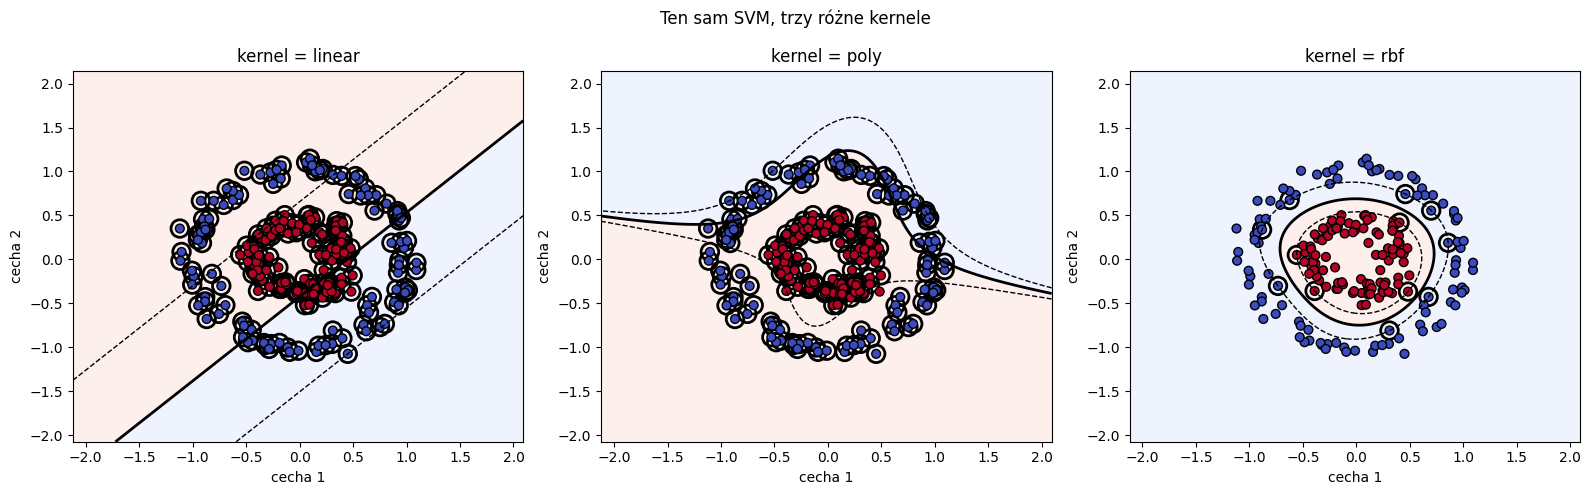

In [27]:
kernele = ["linear", "poly", "rbf"]

fig, osie = plt.subplots(1, 3, figsize=(16, 5))

for os, kernel in zip(osie, kernele):
    model = SVC(kernel=kernel, C=1000)
    model.fit(X_kolo, y_kolo)
    narysuj_svm(model, X_kolo, os)
    os.scatter(X_kolo[:, 0], X_kolo[:, 1], c=y_kolo, cmap="coolwarm", s=40, edgecolors="k")
    os.set_title(f"kernel = {kernel}")
    os.set_xlabel("cecha 1")
    os.set_ylabel("cecha 2")

plt.suptitle("Ten sam SVM, trzy różne kernele")
plt.tight_layout()
plt.show()

## Wnioski

- SVM szuka granicy środkiem **najszerszego marginesu**,
- o granicy decydują tylko **wektory podpierające** — punkty przy krawędzi ulicy,
- nowy punkt klasyfikujemy po stronie granicy; odległość od niej = pewność,
- gdy prosta nie wystarcza, **kernel** pozwala SVM działać jak w wyższym wymiarze,
- kernel **RBF** to domyślny wybór dla danych nieliniowych.